# Is an added base-to-ground capacitor needed for the two-loop oscillator?

The preceding oscillating model had **no added base-to-ground capacitor**. Its 100 nF capacitors were each **between the transistor base and photodiode cathode**, in parallel with 1 MΩ. Intrinsic transistor base charge and photodiode junction charge were retained. This notebook adds a separate C_G from each Q1 base to ground, leaving the branch capacitors, resistors and crossed optical connection unchanged.

Both boards retain constant 5 V DC, OPA380 → 10 kΩ → Q1 base, Q1 emitter grounded, +5 V → laser → collector, and BPW34 anode grounded. Laser A illuminates photodiode B and vice versa with assumed κ=0.5. C_G is varied from zero through nF values to the former 2,200 µF value. Identical added capacitance is used on both boards. No inductor, flyback diode, Q2, timer or imposed switching threshold is present.

The purpose is to separate numerical evidence for the oscillator from physical validation, and determine whether extra base storage preserves or damps it. The existing conditional OPA380 high branch is outside its specified input common-mode range; its actual behavior there is unknown. The laser model has no identified module driver or current limiter. Semiconductor charge parameters are inherited rather than switching-time fitted. These uncertainties can affect the existence of physical oscillation, not merely its amplitude and frequency.

In [1]:
from pathlib import Path
import os,sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import brentq
from IPython.display import display,Markdown
ROOT=Path(os.environ.get('TWIN_PROJECT_ROOT','.'))
sys.path.insert(0,os.environ.get('TWIN_COMPONENT_PATH',str(ROOT/'03_code')))
from twin_components.cross_coupled_parallel_rc import CrossCoupledParallelRC
from twin_components.series_rc_pair import SeriesRCPair
OUTPUT=Path(os.environ.get('TWIN_OUTPUT_ROOT',str(ROOT)))
OUT=OUTPUT/'03_code/notebooks/twin_output/base_ground_capacitor_study';OUT.mkdir(parents=True,exist_ok=True)
FIG=OUTPUT/'06_figures';FIG.mkdir(parents=True,exist_ok=True)
raw=ROOT/'02_data/hysteresis_experiment_0.csv';raw_hash=hashlib.sha256(raw.read_bytes()).hexdigest()
BASE=ROOT/'03_code/notebooks/twin_output/two_loop_parallel_rc'
baseline=pd.read_csv(BASE/'cross_precharged.csv')
baseline_summary=json.loads((BASE/'results_summary.json').read_text())
assert all(baseline_summary['checks'].values())
def save(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),dpi=180,bbox_inches='tight')
    plt.show()
m=CrossCoupledParallelRC();e=m.original.equilibrium(.5)
v=e['VBE_V'];u=v-e['pd_cathode_V'];dc=np.array([v,u,v,u])
specs=pd.read_csv(ROOT/'01_hardware/part_tables/red_laser_specs.csv');display(specs)


,Parameter,Typical Value
0,Wavelength,650 nm (visible red)
1,Operating Voltage,2.2V – 3.3V
2,Threshold Current,~20–30 mA
3,Operating Current,30–50 mA
4,Optical Output,3–5 mW (low power class IIIa)
5,Beam Divergence,"~8° parallel, ~30° perpendicular"
6,Package,TO-18 or 5.6mm can
7,Modulation,Up to ~20 MHz (with proper drive)


## Why the model predicts 8.5 mW peaks

The local `red_laser_specs.csv` is a generic summary: nominal optical output 3–5 mW, operating current 30–50 mA and threshold roughly 20–30 mA. It is not an identified manufacturer laser-module datasheet. The current model assumes a bare laser plus 25 Ω passive series resistance; it does not reconstruct unidentified active module electronics.

Near and above threshold, its optical law approaches
$$P\simeq\eta_s(I_L-I_{th}),\quad\eta_s=0.20\ \mathrm{W/A},\quad I_{th}=25\ \mathrm{mA}.$$
These are chosen priors. A transient near 67.5 mA therefore gives about $0.20(0.0675-0.025)=8.5$ mW. When the opposite laser dims, the branch capacitor can temporarily return current to the base rather than only drawing current away. That raises transistor drive and produces an optical overshoot in the model. The next cell checks the stored current trace at that peak.

The result is not automatically mathematically invalid: 67.5 mA is inside the model's demonstration domain. It is **outside the generic nominal operating-current description**. A real module might limit current, produce a different L–I curve, or be operated beyond its intended condition. The 3–5 mW entry is not a justified hard clipping law. Artificially capping plotted output would also change the optical feedback without establishing the real circuit physics.

The 64.5 kHz frequency likewise comes from the retained charge equations and quasi-static collector/laser mapping. Finer integration checks numerical consistency of those equations, not the truth of their parameter values. Unknown charge storage, module dynamics, amplifier behavior, wiring and capacitor ESR can change transitions and loop stability.

,peak_optical_mW,peak_laser_current_mA,peak_base_current_mA,opamp_base_drive_mA,branch_capacitor_current_mA,branch_resistor_current_mA,linear_above_threshold_mW
0,8.500182,67.498115,0.703991,0.376878,-0.328401,0.001234,8.499623


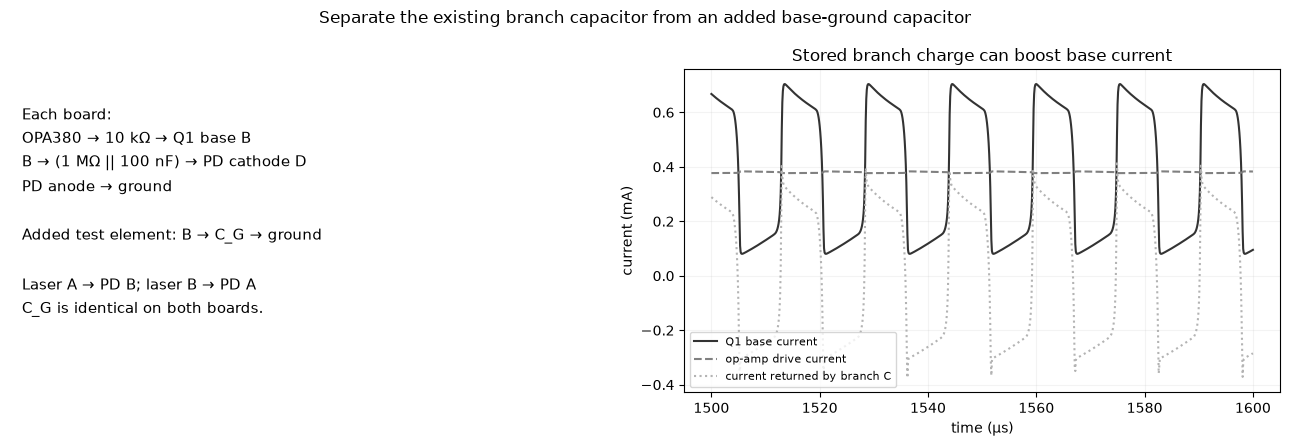

In [2]:
late=baseline[baseline.time_s>=.001]
peak=late.loc[late.A_laser_W.idxmax()]
lp=m.dev.laser.p
explanation=dict(peak_optical_mW=peak.A_laser_W*1e3,peak_laser_current_mA=peak.A_laser_A*1e3,peak_base_current_mA=peak.A_base_A*1e3,opamp_base_drive_mA=peak.A_drive_A*1e3,branch_capacitor_current_mA=peak.A_branch_capacitor_A*1e3,branch_resistor_current_mA=peak.A_resistor_A*1e3,linear_above_threshold_mW=max(0,lp.slope_W_A*(peak.A_laser_A-lp.threshold_A))*1e3)
display(pd.DataFrame([explanation]));pd.DataFrame([explanation]).to_csv(OUT/'peak_current_explanation.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
axs[0].axis('off')
axs[0].text(.02,.9,'Each board:\nOPA380 → 10 kΩ → Q1 base B\nB → (1 MΩ || 100 nF) → PD cathode D\nPD anode → ground\n\nAdded test element: B → C_G → ground\n\nLaser A → PD B; laser B → PD A\nC_G is identical on both boards.',transform=axs[0].transAxes,va='top',fontsize=11,linespacing=1.6)
w=baseline[baseline.time_s.between(.0015,.0016)]
axs[1].plot(w.time_s*1e6,w.A_base_A*1e3,color='.2',label='Q1 base current')
axs[1].plot(w.time_s*1e6,w.A_drive_A*1e3,color='.5',ls='--',label='op-amp drive current')
axs[1].plot(w.time_s*1e6,-w.A_branch_capacitor_A*1e3,color='.7',ls=':',label='current returned by branch C')
axs[1].set(xlabel='time (µs)',ylabel='current (mA)',title='Stored branch charge can boost base current')
axs[1].legend(fontsize=8);axs[1].grid(alpha=.15)
fig.suptitle('Separate the existing branch capacitor from an added base-ground capacitor')
fig.tight_layout();save(fig,'base_ground_capacitor_connections_and_peak')


## Added C_G changes the existing charge equations

The effective base charge derivative becomes $C_{B,total}=C_{B,intrinsic}+C_G$. Every other term is unchanged. In the prior equations,
$$C_{B,total}\dot v_B=I_{drive}-I_B-u/R-C\dot u,$$
$$C_{PD}\,\dot v_D=u/R+C\dot u-i_{PD}.$$

The C_G=0 baseline is loaded from the executed preceding notebook; sampled RHS/current traces below verify that the new optional parameter preserves that default. New cases start near the same symmetric adapted DC point with a 1 mV branch-charge mismatch and run for 1 ms. Because a capacitor is open at DC, adding C_G does not change the DC equilibrium, but it can change its stability.

The local stability crossing is measured from a four-state linearization, not imposed as a switching threshold. A stable DC point does not prove the absence of every other attractor, so a 10 nF dark-start run and a 2,200 µF cold-start run also test distinct initial states.

Local stability crossing C_G (nF): 8.20378219386963


,C_ground_F,max_real_eigenvalue_s,tail_min_mW,tail_max_mW,tail_pkpk_mW,peaks,period_s,frequency_Hz
0,0.000000e+00,379005.754111,0.000159,8.500195,8.500037e+00,32,0.000015,64516.129032
1,1.000000e-09,237639.459784,0.000169,8.503849,8.503679e+00,31,0.000016,62500.000000
2,3.300000e-09,97585.399816,0.000198,8.496428,8.496229e+00,29,0.000017,58823.529412
3,1.000000e-08,-16581.084722,4.203501,4.203505,3.939753e-06,0,NaN,NaN
4,1.000000e-07,-31658.507778,4.203504,4.203504,3.349606e-09,0,NaN,NaN
5,1.000000e-06,-10162.445077,4.203504,4.203543,3.955792e-05,0,NaN,NaN
6,2.200000e-03,-5.916732,4.203504,4.203504,1.117162e-12,0,NaN,NaN


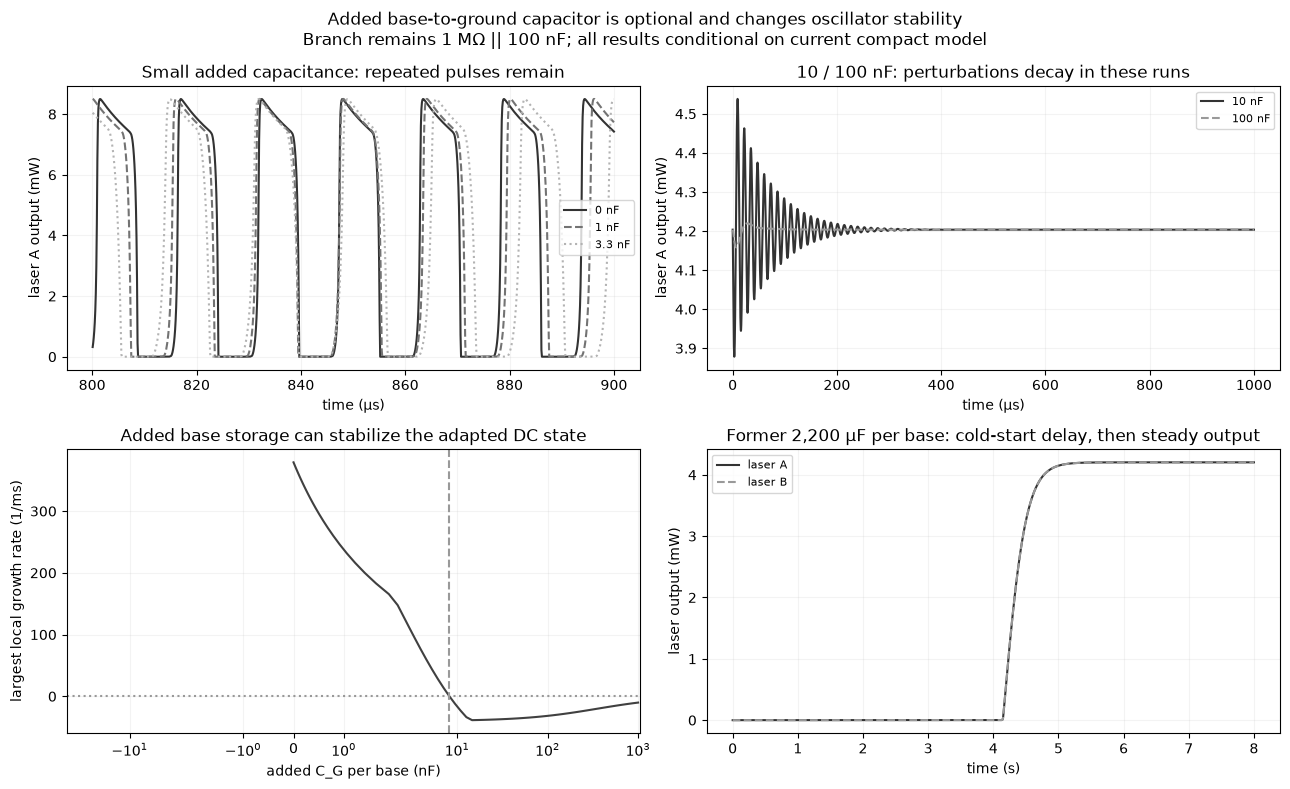

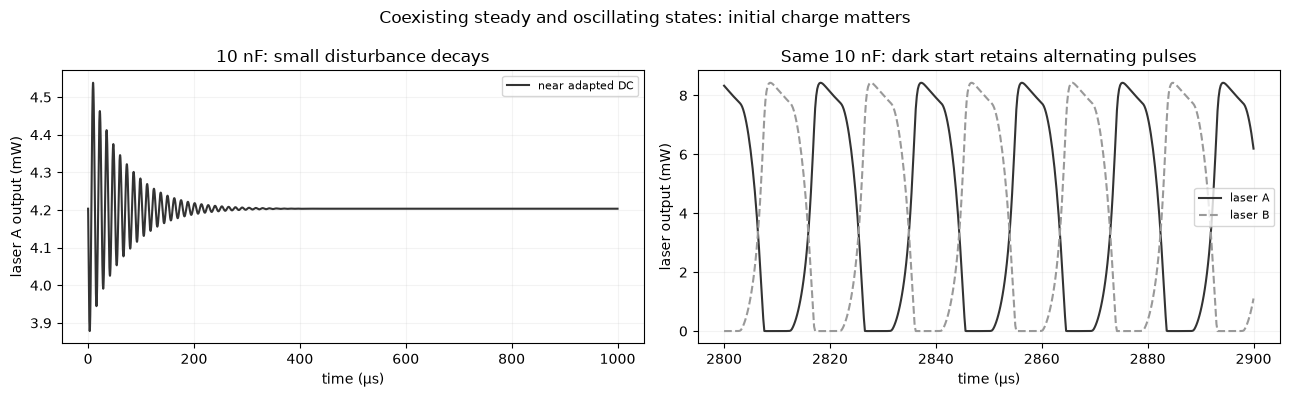

In [3]:
def metrics(f,start=.0005):
    s=f[f.time_s>=start];t=s.time_s.to_numpy();a=s.A_laser_W.to_numpy()
    ix,_=find_peaks(a,prominence=.0002)
    period=float(np.median(np.diff(t[ix]))) if len(ix)>1 else np.nan
    return dict(tail_min_mW=float(a.min()*1e3),tail_max_mW=float(a.max()*1e3),tail_pkpk_mW=float(np.ptp(a)*1e3),peaks=int(len(ix)),period_s=period,frequency_Hz=1/period if np.isfinite(period) else np.nan)
def eigen(cap):
    old=m.C_base_ground;m.C_base_ground=cap
    try:
        h=1e-6;J=np.column_stack([(m.rhs(0,dc+np.eye(4)[j]*h,lambda t:(0.,0.))-m.rhs(0,dc-np.eye(4)[j]*h,lambda t:(0.,0.)))/(2*h) for j in range(4)])
        return np.linalg.eigvals(J)
    finally:m.C_base_ground=old
rows=[dict(C_ground_F=0.,max_real_eigenvalue_s=float(max(eigen(0).real)),**metrics(baseline[baseline.time_s<=.001]))]
frames={0.:baseline[baseline.time_s<=.001].copy()}
for cap in [1e-9,3.3e-9,1e-8,1e-7,1e-6,2200e-6]:
    candidate=CrossCoupledParallelRC(devices=m.dev,C_base_ground=cap)
    f=candidate.run(np.linspace(0,.001,10001),initial=dc+np.array([0,0,0,.001]),rtol=1e-6)
    frames[cap]=f;f.to_csv(OUT/f'C_ground_{cap:g}F.csv',index=False)
    rows.append(dict(C_ground_F=cap,max_real_eigenvalue_s=float(max(eigen(cap).real)),**metrics(f)))
results=pd.DataFrame(rows);display(results);results.to_csv(OUT/'base_capacitor_sweep.csv',index=False)
critical=brentq(lambda c:max(eigen(c).real),3.3e-9,1e-8,xtol=1e-14)
print('Local stability crossing C_G (nF):',critical*1e9)
ten=CrossCoupledParallelRC(devices=m.dev,C_base_ground=10e-9)
darkstart=ten.run(np.linspace(0,.002,10001),initial=[m.dark['VBE_V'],0,m.dark['VBE_V'],.001],rtol=1e-6)
darkstart.to_csv(OUT/'10nF_dark_start.csv',index=False)
fine_devices=SeriesRCPair(resistance=1e6,capacitance=100e-9,coupling=0.,grid_points=2801,rail_points=201,base_min_V=-.65)
refined_ten=CrossCoupledParallelRC(devices=fine_devices,C_base_ground=10e-9)
dark_refined=refined_ten.run(np.linspace(0,.003,15001),initial=[m.dark['VBE_V'],0,m.dark['VBE_V'],.001],rtol=2e-7)
dark_refined.to_csv(OUT/'10nF_dark_start_refined.csv',index=False)
dark_metrics=metrics(darkstart,.001);refined_metrics=metrics(dark_refined,.002)
large=CrossCoupledParallelRC(devices=m.dev,C_base_ground=2200e-6)
cold=large.run(np.linspace(0,8,4001),initial=[0,0,0,.001],rtol=1e-6,max_step=.01)
cold.to_csv(OUT/'2200uF_cold_start.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(13,8))
for j,cap in enumerate([0.,1e-9,3.3e-9]):
    f=frames[cap];w=f[f.time_s.between(.0008,.0009)]
    axs[0,0].plot(w.time_s*1e6,w.A_laser_W*1e3,color=str(.2+j*.25),ls=['-','--',':'][j],label=f'{cap*1e9:g} nF')
for j,cap in enumerate([1e-8,1e-7]):
    f=frames[cap];axs[0,1].plot(f.time_s*1e6,f.A_laser_W*1e3,color=str(.2+j*.4),ls=['-','--'][j],label=f'{cap*1e9:g} nF')
axs[0,0].set(title='Small added capacitance: repeated pulses remain',xlabel='time (µs)',ylabel='laser A output (mW)')
axs[0,1].set(title='10 / 100 nF: perturbations decay in these runs',xlabel='time (µs)',ylabel='laser A output (mW)')
caps=np.r_[0.,np.geomspace(1e-11,1e-6,80)]
vals=[max(eigen(c).real) for c in caps]
axs[1,0].plot(caps*1e9,np.array(vals)/1e3,color='.25');axs[1,0].axhline(0,color='.6',ls=':');axs[1,0].axvline(critical*1e9,color='.6',ls='--')
axs[1,0].set(xscale='symlog',xlabel='added C_G per base (nF)',ylabel='largest local growth rate (1/ms)',title='Added base storage can stabilize the adapted DC state')
axs[1,1].plot(cold.time_s,cold.A_laser_W*1e3,color='.2',label='laser A');axs[1,1].plot(cold.time_s,cold.B_laser_W*1e3,color='.6',ls='--',label='laser B')
axs[1,1].set(xlabel='time (s)',ylabel='laser output (mW)',title='Former 2,200 µF per base: cold-start delay, then steady output')
for ax in [axs[0,0],axs[0,1],axs[1,1]]:ax.legend(fontsize=8)
for ax in axs.flat:ax.grid(alpha=.15)
fig.suptitle('Added base-to-ground capacitor is optional and changes oscillator stability\nBranch remains 1 MΩ || 100 nF; all results conditional on current compact model')
fig.tight_layout();save(fig,'base_ground_capacitor_sweep')
fig,axs=plt.subplots(1,2,figsize=(13,4))
near=frames[1e-8]
axs[0].plot(near.time_s*1e6,near.A_laser_W*1e3,color='.2',label='near adapted DC')
axs[0].set(title='10 nF: small disturbance decays',xlabel='time (µs)',ylabel='laser A output (mW)')
w=dark_refined[dark_refined.time_s.between(.0028,.0029)]
axs[1].plot(w.time_s*1e6,w.A_laser_W*1e3,color='.2',label='laser A')
axs[1].plot(w.time_s*1e6,w.B_laser_W*1e3,color='.6',ls='--',label='laser B')
axs[1].set(title='Same 10 nF: dark start retains alternating pulses',xlabel='time (µs)',ylabel='laser output (mW)')
for ax in axs:ax.grid(alpha=.15);ax.legend(fontsize=8)
fig.suptitle('Coexisting steady and oscillating states: initial charge matters')
fig.tight_layout();save(fig,'base_ground_capacitor_coexistence')


## Checks and conclusions

The baseline numerical checks do not validate the real laser power curve or device switching parameters. This comparison verifies the effect of a precisely placed extra capacitor within the same equations. Thresholds and period values below are parameter-dependent, not component tolerances for a hardware design.

In [4]:
# Ensure the updated optional C_G leaves the old zero-added-C equations intact.
baseline_error=[]
for r in baseline.iloc[::150].itertuples():
    y=[r.A_base_V,r.A_capacitor_V,r.B_base_V,r.B_capacitor_V]
    for label,p in zip('AB',m.point(y)):
        baseline_error.extend([abs(p['dbase_V_s']-getattr(r,label+'_dbase_V_s')),abs(p['dcapacitor_V_s']-getattr(r,label+'_dcapacitor_V_s'))])
node_error=[]
for cap,f in frames.items():
    for r in f.iloc[::300].itertuples():
        for label in 'AB':
            get=lambda name:getattr(r,label+'_'+name)
            branch=get('resistor_A')+get('branch_capacitor_A')
            node_error.append(abs(get('drive_A')-get('base_A')-branch-get('base_C_F')*get('dbase_V_s')))
checks={
 'zero-added-C baseline RHS unchanged':max(baseline_error)<1e-6,
 'base node KCL below 1 nA':max(node_error)<1e-9,
 'baseline oscillates without added C_G':results.iloc[0].peaks>=20,
 '1 nF and 3.3 nF retain repeated peaks':all(results.loc[results.C_ground_F.isin([1e-9,3.3e-9]),'peaks']>=20),
 '10 nF and 100 nF seeded cases decay':all(results.loc[results.C_ground_F.isin([1e-8,1e-7]),'tail_pkpk_mW']<.01),
 '10 nF dark-start retains repeated peaks':dark_metrics['peaks']>=20 and refined_metrics['peaks']>=20,
 '10 nF dark-start refined period agrees within 5 percent':abs(refined_metrics['period_s']/dark_metrics['period_s']-1)<.05,
 '10 nF dark-start refined amplitude agrees within 5 percent':abs(refined_metrics['tail_pkpk_mW']/dark_metrics['tail_pkpk_mW']-1)<.05,
 '2200 uF cold-start approaches steady DC':max(abs(cold.A_laser_W.iloc[-1]-e['laser_W']),abs(cold.B_laser_W.iloc[-1]-e['laser_W']))<1e-7,
 'local stability boundary lies within tested bracket':3.3e-9<critical<1e-8,
 'peak current exceeds generic 50 mA operating summary':explanation['peak_laser_current_mA']>50,
 'branch capacitor returns current at optical peak':explanation['branch_capacitor_current_mA']<0,
 'raw data unchanged':hashlib.sha256(raw.read_bytes()).hexdigest()==raw_hash}
assert all(checks.values()),checks
display(pd.DataFrame({'check':checks.keys(),'passed':checks.values()}))
summary=dict(peak_explanation=explanation,local_stability_C_ground_F=critical,dark_start_10nF=dark_metrics,dark_start_10nF_refined=refined_metrics,checks={k:bool(v) for k,v in checks.items()},hardware_validated=False,current_and_optical_limits_identified=False)
(OUT/'results_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
display(Markdown(f'**Model conclusion:** an added base-to-ground capacitor is not required for the demonstrated mode. Small added nF values alter its timing. At 10 nF, a small disturbance near adapted DC decays, but dark-start initial charge produces sustained alternating pulses; a refined, longer run retains them. Thus steady emission and oscillation coexist for that tested value. The local stability crossing near **{critical*1e9:.2f} nF** is not a global oscillation cutoff. The former 2,200 µF value gives a long startup transient and steady emission in the tested cold start. These results remain conditional on the compact model.'))


,check,passed
0,zero-added-C baseline RHS unchanged,True
1,base node KCL below 1 nA,True
2,baseline oscillates without added C_G,True
3,1 nF and 3.3 nF retain repeated peaks,True
4,10 nF and 100 nF seeded cases decay,True
5,10 nF dark-start retains repeated peaks,True
6,10 nF dark-start refined period agrees within ...,True
7,10 nF dark-start refined amplitude agrees with...,True
8,2200 uF cold-start approaches steady DC,True
9,local stability boundary lies within tested br...,True


**Model conclusion:** an added base-to-ground capacitor is not required for the demonstrated mode. Small added nF values alter its timing. At 10 nF, a small disturbance near adapted DC decays, but dark-start initial charge produces sustained alternating pulses; a refined, longer run retains them. Thus steady emission and oscillation coexist for that tested value. The local stability crossing near **8.20 nF** is not a global oscillation cutoff. The former 2,200 µF value gives a long startup transient and steady emission in the tested cold start. These results remain conditional on the compact model.

## Sources and rerun

The user requested an explanation of provisional peaks/frequency and verification of the base-ground capacitor. Device source status comes directly from the supplied project component models and `01_hardware/part_tables/red_laser_specs.csv`. That file is a generic summary, not an identified module curve. Numerical refinement and conservation checks support the computed mode; a measured L–I/V–I curve, module current limiting and valid amplifier operation are still needed to validate a physical oscillator. No historical data are fitted or changed.

Run all cells in the project environment after the preceding `two_loop_parallel_rc.ipynb`, whose executed C_G=0 trajectory is the control. Optional TWIN_PROJECT_ROOT, TWIN_COMPONENT_PATH and TWIN_OUTPUT_ROOT redirect roots. Tables are in `twin_output/base_ground_capacitor_study`; figures are in `06_figures/base_ground_capacitor_*`. No instruments are controlled.